# Lab 06: Object Detection and Image Segmentation

**ITAI 1378  |  Module 06 Companion Lab  |  2026**

**Author:** Patricia McManus     **Collaborator:** Claude (Anthropic)

**Course:** AI and Robotics Program, Digital and Information Technology Center of Excellence, Houston City College

---

In this lab you will work with two of the most useful and most asked-about computer vision tasks: **object detection** (drawing boxes around things) and **image segmentation** (outlining each thing exactly). You will use modern 2026 tools that real CV engineers use every day. You will also see how a specialized detector compares to a foundation model.

This is the lab where the **midterm project gets introduced**, so plan to leave time at the end to start thinking about what you want to build.

## What you will be able to do by the end of this lab

By the end of this lab you will be able to:

- Explain how classification, detection, and segmentation differ.
- Run a modern object detector on any image and read its output.
- Run an instance segmenter and visualize the masks it produces.
- Compare a specialist detector (YOLO11) with a foundation model (SAM 2).
- Talk about evaluation metrics (IoU, precision, recall, mAP) in plain English.
- Pick a midterm project direction that uses the techniques from Modules 1 through 6.

## What you will NOT have to do

- Implement any math from scratch.
- Train a model from zero (we use pretrained weights throughout).
- Use anything outside a free Google Colab account.

If you can copy code into a cell and press Run, you can do this lab.

---

## 1.  The Three CV Tasks Side by Side

Before we touch any code, let's make sure the three core CV tasks are clear in your head. Every CV system you will ever encounter is some variation on these three.

**Image Classification** answers the question: *what is in this image?*

The output is one label for the whole image. For example: this is a picture of a cat. No location, no count, no shape.

**Object Detection** answers: *what is in this image, and where is each thing?*

The output is a list of labeled rectangles, called bounding boxes. For example: cat at the upper left, dog at the lower right. You get the type and the approximate location of each object.

**Image Segmentation** answers: *which exact pixels belong to each thing?*

The output is a pixel-level mask for each object. For example: these 4,521 pixels are the cat, those 8,832 pixels are the dog. You get the precise outline, not just a rectangle.

### Which task is right for which job?

- **Classification:** Sorting a photo library by category. Detecting whether a product image has a logo or not.
- **Detection:** Counting cars in a parking lot. Spotting a person in a hazard zone. Reading license plates.
- **Segmentation:** Medical imaging where exact organ outlines matter. Background removal for video calls. Robot arms that need to grasp specific objects.

Today we focus on detection and segmentation. Module 5 already covered classification.

---

## 2.  Setup

We will use the **Ultralytics** library, which is the standard 2026 toolkit for working with YOLO detection and segmentation models. It also wraps Meta's SAM 2 foundation model, so we get both worlds with one library install.

Run the cell below to install Ultralytics. The first time this runs in a fresh Colab notebook it will take about a minute.

In [1]:
# Install the Ultralytics library
# This gives us YOLO11 (detection and segmentation) and SAM 2 (foundation model) in one package.
%pip install -q ultralytics

# Quick check that everything imported successfully
from ultralytics import YOLO, SAM
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

print("Setup complete. Ready to detect and segment.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 6.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Setup complete. Ready to detect and segment.


---

## 3.  Load a Sample Image

Ultralytics ships with a few sample images we can use without uploading anything ourselves. We will start with one that contains several common objects (people, a bus, etc.) so the detector and segmenter have something interesting to find.

You can also upload your own image to Colab later by clicking the folder icon in the left sidebar and dragging a file in.

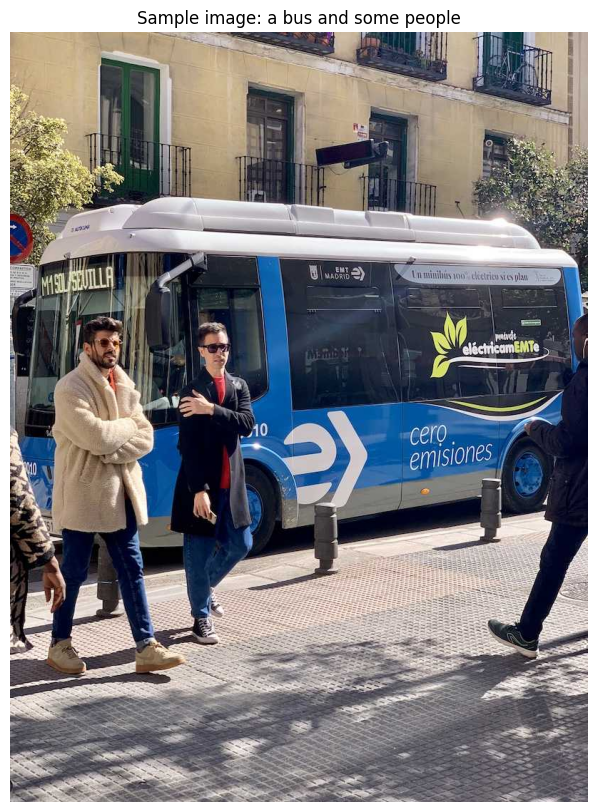

Image size: 810 wide by 1080 tall pixels


In [2]:
# This is a sample image that ships with the Ultralytics package
SAMPLE_IMAGE = "https://ultralytics.com/images/bus.jpg"

# Display it so we know what we're working with
img = Image.open(__import__("urllib.request", fromlist=["urlretrieve"]).urlretrieve(SAMPLE_IMAGE)[0])
plt.figure(figsize=(8, 10))
plt.imshow(img)
plt.axis("off")
plt.title("Sample image: a bus and some people")
plt.show()

print(f"Image size: {img.size[0]} wide by {img.size[1]} tall pixels")

---

## 4.  Object Detection with YOLO11

YOLO11 is the current production-default real-time object detector from Ultralytics, released in September 2024 and still recommended for most workforce use cases in 2026. It is a *specialist* model: it was trained specifically to find and box 80 common object categories like person, car, dog, traffic light, and so on (the COCO dataset categories).

### Why YOLO

The YOLO family is popular because it is:
- **Fast.** Many YOLO variants run in real time, even on a laptop.
- **Accurate enough for most jobs.** Good general purpose performance on common objects.
- **Easy to use.** Two lines of code to load and run.
- **Available in many sizes.** Pick a tiny version for an edge device, or a large version for a workstation.

### Loading the model

We will use **yolo11n**, the smallest "nano" version. Small enough to run on free Colab, fast enough to demo live.

In [3]:
# Load a pretrained YOLO11 nano model
# The first run downloads the weights automatically (about 5 MB).
detector = YOLO("yolo11n.pt")

print("YOLO11 nano loaded.")
print(f"Number of object classes it knows: {len(detector.names)}")
print(f"First ten classes: {list(detector.names.values())[:10]}")

YOLO11 nano loaded.
Number of object classes it knows: 80
First ten classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']


### Running detection

Detection is now just one line. The model takes an image and returns a results object with boxes, labels, and confidence scores.


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 485.4ms
Speed: 31.9ms preprocess, 485.4ms inference, 40.2ms postprocess per image at shape (1, 3, 640, 480)


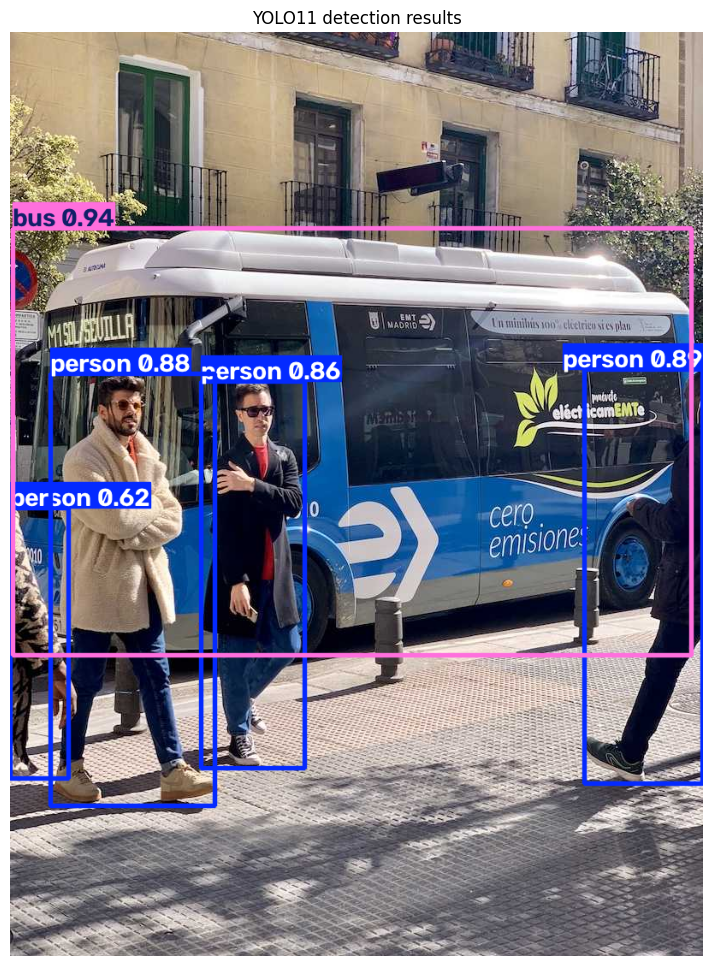

In [4]:
# Run detection on the sample image
results = detector(SAMPLE_IMAGE)

# The results object has built-in visualization
# results[0].plot() returns an annotated image as a numpy array (in BGR format)
annotated = results[0].plot()

# Convert BGR (OpenCV style) to RGB (Matplotlib style) for display
annotated_rgb = annotated[..., ::-1]

plt.figure(figsize=(10, 12))
plt.imshow(annotated_rgb)
plt.axis("off")
plt.title("YOLO11 detection results")
plt.show()

### Reading the output

The results object also gives us the raw information so we can do our own analysis. Let's see what the model actually found.

In [5]:
# Print a summary of what the detector found
print("DETECTED OBJECTS")
print("=" * 50)

# results[0].boxes has the detection details
boxes = results[0].boxes

# Loop through each detected object
for i in range(len(boxes)):
    class_id = int(boxes.cls[i])
    class_name = detector.names[class_id]
    confidence = float(boxes.conf[i])
    # xyxy gives [x_min, y_min, x_max, y_max] in pixel coordinates
    x_min, y_min, x_max, y_max = boxes.xyxy[i].tolist()

    print(f"  {class_name:<15} confidence: {confidence:.2%}    "
          f"box: ({int(x_min)}, {int(y_min)}) to ({int(x_max)}, {int(y_max)})")

print(f"\nTotal objects detected: {len(boxes)}")

DETECTED OBJECTS
  bus             confidence: 94.02%    box: (3, 229) to (796, 728)
  person          confidence: 88.82%    box: (671, 394) to (809, 878)
  person          confidence: 87.83%    box: (47, 399) to (239, 904)
  person          confidence: 85.58%    box: (223, 408) to (344, 860)
  person          confidence: 62.19%    box: (0, 556) to (68, 872)

Total objects detected: 5


---

### Your Turn 1: Try It on a Different Image

Run the detector on a different image and see what it finds. You have two options:

**Option A:** Use another Ultralytics sample image. Try one of these URLs by changing `my_image` below:
- `https://ultralytics.com/images/zidane.jpg`  (two people on a soccer field)
- `https://ultralytics.com/images/bus.jpg`  (the one we already saw)

**Option B:** Upload your own image. Click the folder icon in the left Colab sidebar, drag in a JPG or PNG, then set `my_image` to its filename (something like `"/content/my_photo.jpg"`).

**What to do:**
1. Set `my_image` to your chosen URL or filename.
2. Run the cell.
3. Look at the output and answer: did the model find what you expected? Was anything missed or wrong?


image 1/1 /content/Henry-Gigi.jpg: 640x384 2 cats, 142.9ms
Speed: 5.2ms preprocess, 142.9ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 384)


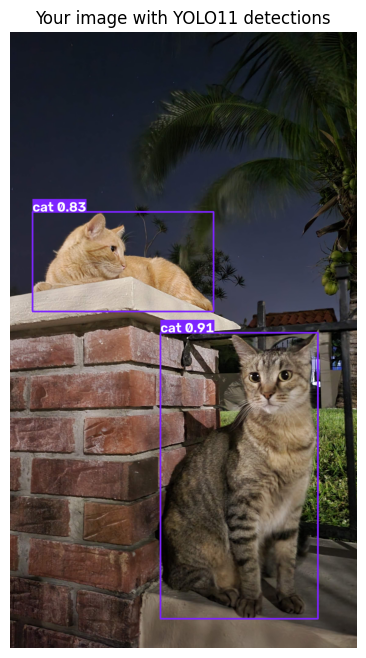

Detected:
  cat (91%)
  cat (83%)


In [6]:
# Change this to your image URL or uploaded file path
my_image = "Henry-Gigi.jpg"

# Run detection
my_results = detector(my_image)
annotated = my_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 8))
plt.imshow(annotated)
plt.axis("off")
plt.title("Your image with YOLO11 detections")
plt.show()

# Show what was detected
print("Detected:")
for i in range(len(my_results[0].boxes)):
    name = detector.names[int(my_results[0].boxes.cls[i])]
    conf = float(my_results[0].boxes.conf[i])
    print(f"  {name} ({conf:.0%})")

---

### Experiment: Confidence Threshold

Every detection comes with a confidence score from 0 to 1. By default, YOLO11 only shows detections with confidence above about 0.25. You can change this threshold.

**Lower threshold** (say 0.10): more detections, including more wrong ones.

**Higher threshold** (say 0.70): fewer detections, but the ones you keep are more likely to be right.

This is a real trade-off you will make in production work. A workplace safety system that watches for people in hazard zones might want a LOW threshold (better to false-alarm than miss someone). A consumer photo tagger might want a HIGH threshold (better to miss a few than to mis-tag a lot).

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
Found https://ultralytics.com/images/bus.jpg locally at bus.jpg


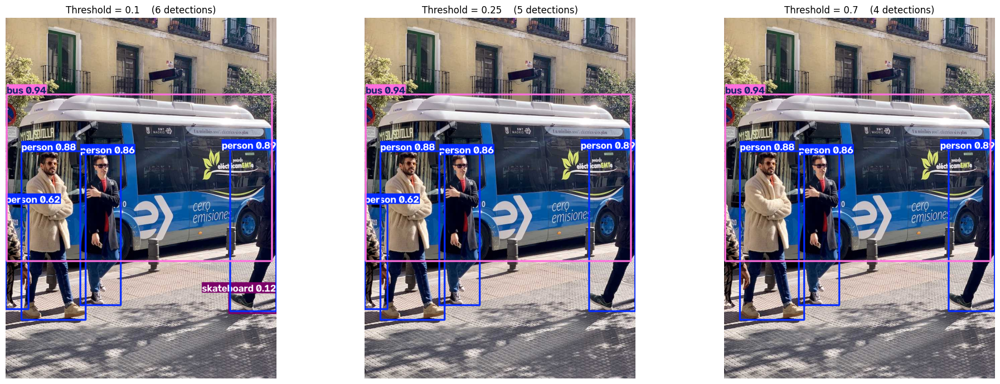

Notice how the number of detections changes with the threshold.
Which threshold would you pick for a workplace safety alert? For a photo tagger?


In [7]:
# Try detection at three different confidence thresholds
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, threshold in zip(axes, [0.10, 0.25, 0.70]):
    r = detector(SAMPLE_IMAGE, conf=threshold, verbose=False)
    ax.imshow(r[0].plot()[..., ::-1])
    ax.axis("off")
    ax.set_title(f"Threshold = {threshold}    "
                 f"({len(r[0].boxes)} detections)")

plt.tight_layout()
plt.show()

print("Notice how the number of detections changes with the threshold.")
print("Which threshold would you pick for a workplace safety alert? For a photo tagger?")

Which threshold would you pick for a workplace safety alert? For a photo tagger?

For a workplace safety alert, I would use a lower confidence threshold because missing a real person or hazard could be more serious than generating an occasional false alert. For a photo tagger, I would use a higher threshold because incorrect labels would be annoying, while missing an uncertain object would be less critical.

---

### Quick Note: Non-Maximum Suppression (NMS)

You may have noticed that YOLO does not give you forty overlapping boxes around the same bus. That is because of **Non-Maximum Suppression**, abbreviated NMS. It is a cleanup step that runs after the model produces its raw guesses.

**In plain English:** NMS looks at all the boxes the model produced, finds groups of boxes that overlap heavily and have the same label, and keeps only the highest-confidence box from each group. The rest get suppressed (deleted).

You do not have to implement NMS yourself. YOLO does it automatically. But knowing what NMS is matters in interviews, because every detection system has one. Some newer models, like YOLO26 released in January 2026, are "NMS-free" by design, but most detectors you will encounter still use it.

---

## 5.  Instance Segmentation with YOLO11-seg

Now we step up from boxes to exact pixel outlines. **Instance segmentation** is the task of producing a pixel-level mask for each individual object, not just a rectangle.

Why this matters:
- A box around a person tells you *where roughly* the person is. A mask tells you *exactly which pixels* are the person, which is what a video editor or a robot arm needs.
- Boxes always include some background. Masks do not.
- Boxes cannot distinguish two overlapping objects very well. Masks can.

Ultralytics has a segmentation version of YOLO11 called **yolo11n-seg**. It outputs both boxes and masks. Loading and running is the same pattern.


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 227.7ms
Speed: 4.4ms preprocess, 227.7ms inference, 15.4ms postprocess per image at shape (1, 3, 640, 480)


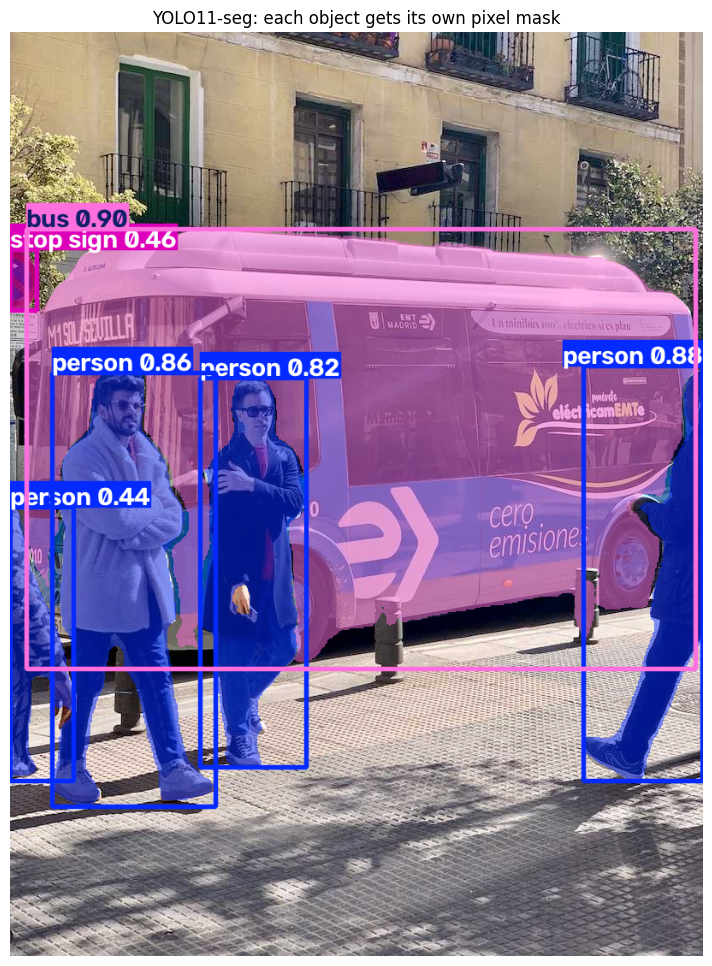

In [8]:
# Load the YOLO11 nano segmentation model
segmenter = YOLO("yolo11n-seg.pt")

# Run it on the same sample image
seg_results = segmenter(SAMPLE_IMAGE)

# Visualize with built-in plotting
annotated = seg_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 12))
plt.imshow(annotated)
plt.axis("off")
plt.title("YOLO11-seg: each object gets its own pixel mask")
plt.show()

### Reading segmentation output

A segmentation result has both `boxes` (same as detection) AND `masks` (the new part). Each mask is a binary image the same size as the input: 1 where the object is, 0 where it is not.

Number of objects with masks: 6
Each mask shape: torch.Size([640, 480])    (this is height x width, one pixel per cell)



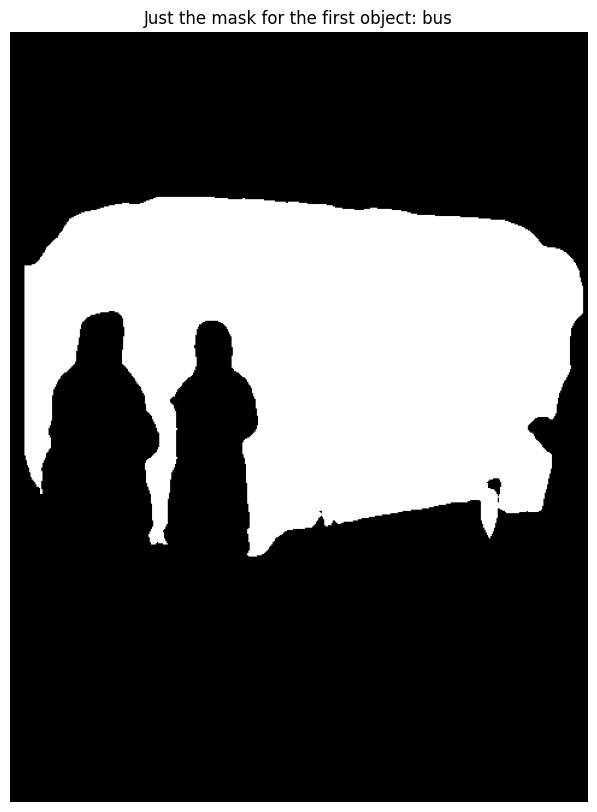

In [9]:
# Show information about the masks
masks = seg_results[0].masks

if masks is not None:
    print(f"Number of objects with masks: {len(masks)}")
    print(f"Each mask shape: {masks.data[0].shape}    "
          "(this is height x width, one pixel per cell)")
    print()

    # Show the first mask on its own so the shape is visible
    first_mask = masks.data[0].cpu().numpy()
    first_label = segmenter.names[int(seg_results[0].boxes.cls[0])]

    plt.figure(figsize=(8, 10))
    plt.imshow(first_mask, cmap="gray")
    plt.axis("off")
    plt.title(f"Just the mask for the first object: {first_label}")
    plt.show()
else:
    print("No masks produced for this image.")

---

### Detection Versus Segmentation Side by Side

Let's put the two results next to each other so the difference is visual and obvious.

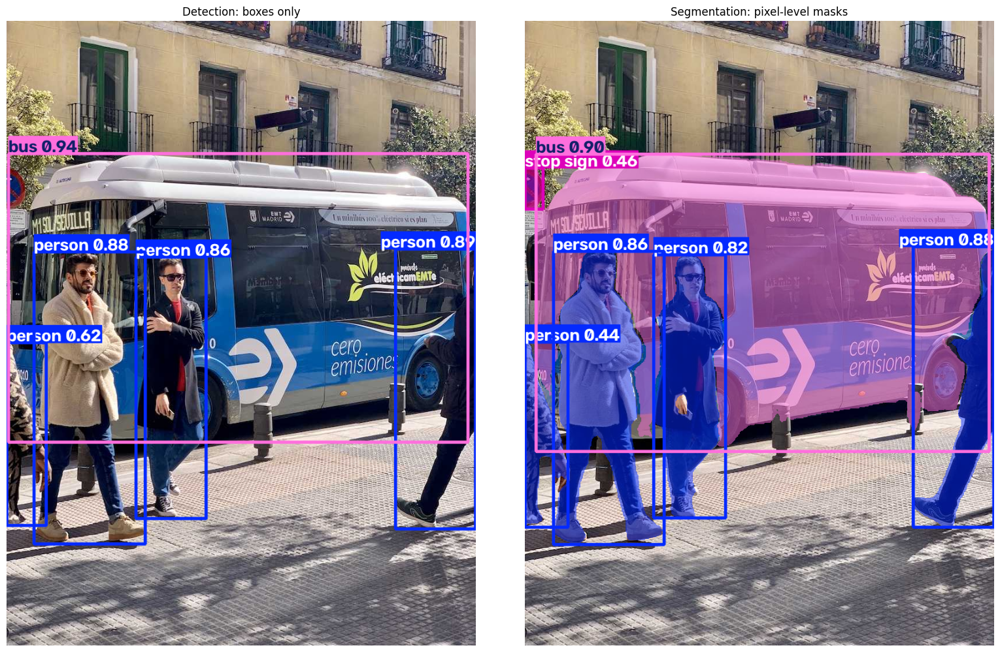

Same image, two different levels of detail.
Detection is faster. Segmentation gives more precise outlines.


In [10]:
# Side by side comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

axes[0].imshow(results[0].plot()[..., ::-1])
axes[0].axis("off")
axes[0].set_title("Detection: boxes only")

axes[1].imshow(seg_results[0].plot()[..., ::-1])
axes[1].axis("off")
axes[1].set_title("Segmentation: pixel-level masks")

plt.tight_layout()
plt.show()

print("Same image, two different levels of detail.")
print("Detection is faster. Segmentation gives more precise outlines.")

---

### Your Turn 2: Segment Your Image

Run YOLO11-seg on the same image you used in Your Turn 1.

**What to look for:**
- Are the masks tight to the objects, or do they bleed into the background?
- Do overlapping objects get separated cleanly?
- Are there any pixels obviously assigned to the wrong object?

The answers tell you something about where this specialist model is strong and where it has limits.


image 1/1 /content/Henry-Gigi.jpg: 640x384 2 cats, 167.7ms
Speed: 4.2ms preprocess, 167.7ms inference, 4.2ms postprocess per image at shape (1, 3, 640, 384)


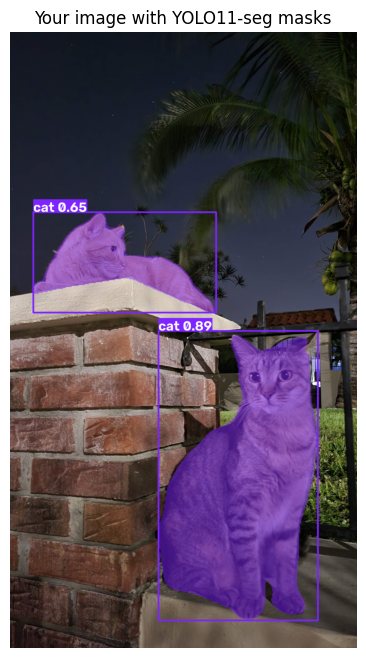

YOLO11-seg produced 2 masks.
Look at the visualization above and judge:
  • Are the masks tight around the objects, or sloppy?
  • Did any objects get missed?


In [11]:
# Use your image from Your Turn 1
# my_image was set earlier; change it again if you want a different one

my_seg_results = segmenter(my_image)
annotated = my_seg_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 8))
plt.imshow(annotated)
plt.axis("off")
plt.title("Your image with YOLO11-seg masks")
plt.show()

# How tight are the masks?
masks = my_seg_results[0].masks
if masks is not None:
    print(f"YOLO11-seg produced {len(masks)} masks.")
    print("Look at the visualization above and judge:")
    print("  • Are the masks tight around the objects, or sloppy?")
    print("  • Did any objects get missed?")

Are the masks tight around the objects, or sloppy?  Did any objects get missed?

The masks were fairly tight around both cats, especially the lower cat, whose full body was clearly visible. The upper cat’s mask was less precise because part of its body was hidden behind the wall, which also corresponded with a lower confidence score. Both cats were detected, so no objects were missed.

---

## 6.  Foundation Models for Segmentation: SAM 2

YOLO11-seg is a **specialist**. It was trained to recognize 80 specific COCO categories and to segment those. If you point it at a teapot, a brain MRI scan, or a satellite image, the categories it knows do not apply and the masks may look strange.

**Segment Anything Model 2** (SAM 2) from Meta is a different beast: it is a **foundation model** for segmentation. It does not know category labels at all. Instead, you point at something with a click, a box, or a prompt, and SAM 2 produces a mask for that thing, whatever it is.

This is a fundamentally different design pattern. Specialists know fixed categories. Foundation models accept prompts and segment whatever you point at.

### The trade-off

| Specialist (YOLO11-seg) | Foundation Model (SAM 2) |
| --- | --- |
| Knows 80 named categories | Knows no named categories |
| Outputs labels + masks | Outputs just masks |
| Very fast | Slower |
| Small model file | Larger model file |
| Easy default for known objects | Required when categories are unknown or unusual |

In a 2026 production pipeline, the two are often used together: YOLO11 finds the objects and labels them, then SAM 2 produces a higher-quality mask using the box as a prompt.

In [12]:
# Load SAM 2 (small variant for Colab compatibility)
# First run downloads about 150 MB of weights.
sam = SAM("sam2.1_s.pt")

print("SAM 2 loaded.")
print("Notice: it does not have a list of class names. SAM 2 segments anything you point at,")
print("but it does not tell you what the thing is called.")

SAM 2 loaded.
Notice: it does not have a list of class names. SAM 2 segments anything you point at,
but it does not tell you what the thing is called.


### Prompting SAM 2 with a box

We can take the boxes that YOLO11 produced and use each one as a prompt to SAM 2. This is the modern "detect then segment with a foundation model" pattern.


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 1024x1024 1 0, 1 1, 1 2, 1 3, 1 4, 10990.9ms
Speed: 16.9ms preprocess, 10990.9ms inference, 35.3ms postprocess per image at shape (1, 3, 1024, 1024)


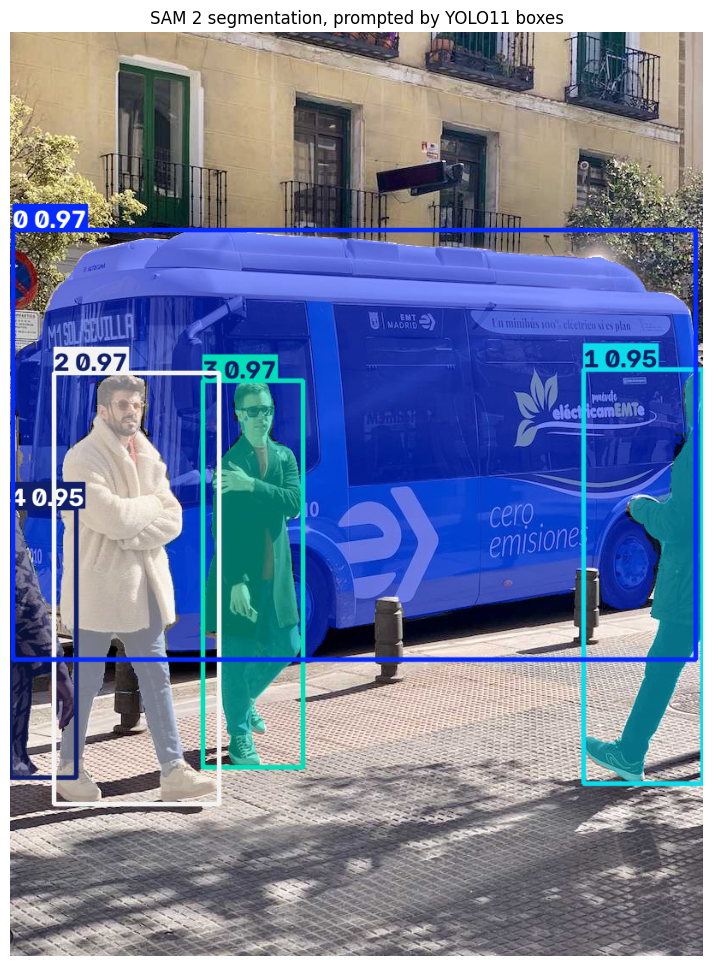

This is the modern detect-then-segment pipeline.
YOLO11 finds and labels the objects. SAM 2 produces high quality masks.


In [13]:
# Use SAM 2 with the boxes YOLO11 found on the sample image
# Pull the boxes from our earlier YOLO11 results
yolo_boxes = results[0].boxes.xyxy.cpu().numpy()

# Run SAM 2 with those boxes as prompts
sam_results = sam(SAMPLE_IMAGE, bboxes=yolo_boxes)

annotated = sam_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 12))
plt.imshow(annotated)
plt.axis("off")
plt.title("SAM 2 segmentation, prompted by YOLO11 boxes")
plt.show()

print("This is the modern detect-then-segment pipeline.")
print("YOLO11 finds and labels the objects. SAM 2 produces high quality masks.")

---

## 7.  Evaluation in Plain English

In a real job you will be asked: "How good is your model?" The honest answer involves several metrics, each measuring something different. None of them require math you have to compute by hand.

### IoU: Intersection over Union

Imagine your model drew a box, and the ground-truth answer also has a box. IoU measures how well they line up.

- If the two boxes match perfectly, IoU is 1.0.
- If they overlap halfway, IoU is around 0.5.
- If they do not overlap at all, IoU is 0.

You will hear people say "IoU above 0.5 counts as a correct detection." That is the most common threshold, but stricter benchmarks use 0.75 or higher.

**You do not need to compute IoU by hand.** Every evaluation tool computes it for you. What you need to know:
- Higher IoU = better localization.
- Different applications need different IoU thresholds. A pedestrian detector for a self-driving car needs high IoU. A photo tagger does not need to be as precise.

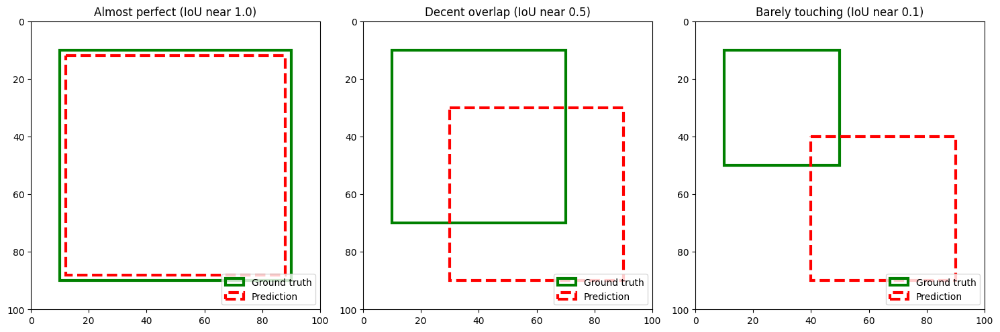

Green = ground truth (the right answer)
Red dashed = the model's prediction
IoU just measures how much they overlap, divided by their combined area.


In [14]:
# Let's see IoU visually, not as math.
# Draw two boxes that overlap by different amounts and label the IoU.
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scenarios = [
    ("Almost perfect (IoU near 1.0)", [10, 10, 90, 90], [12, 12, 88, 88]),
    ("Decent overlap (IoU near 0.5)", [10, 10, 70, 70], [30, 30, 90, 90]),
    ("Barely touching (IoU near 0.1)", [10, 10, 50, 50], [40, 40, 90, 90]),
]

for ax, (title, gt, pred) in zip(axes, scenarios):
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.invert_yaxis()
    # Ground truth in green
    ax.add_patch(Rectangle((gt[0], gt[1]), gt[2]-gt[0], gt[3]-gt[1],
                           edgecolor="green", facecolor="none", linewidth=3, label="Ground truth"))
    # Prediction in red
    ax.add_patch(Rectangle((pred[0], pred[1]), pred[2]-pred[0], pred[3]-pred[1],
                           edgecolor="red", facecolor="none", linewidth=3,
                           linestyle="--", label="Prediction"))
    ax.set_title(title); ax.set_aspect("equal"); ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print("Green = ground truth (the right answer)")
print("Red dashed = the model's prediction")
print("IoU just measures how much they overlap, divided by their combined area.")

### Precision and Recall

These two go together. Think of a smoke alarm.

**Precision:** of all the times the alarm went off, what percent were actual fires?

A precision of 90% means 9 out of 10 alarms were real fires, 1 was a false alarm. High precision = few false alarms.

**Recall:** of all the actual fires, what percent did the alarm catch?

A recall of 90% means the alarm caught 9 out of 10 actual fires, 1 was missed. High recall = few missed events.

There is always a trade-off. Make the alarm more sensitive: precision drops (more false alarms) but recall rises (fewer missed fires). Make it less sensitive: precision rises but recall drops.

### When precision matters more

- A photo tagger that suggests "tag your friend Alice in this photo." A wrong tag is embarrassing. Better to miss than to be wrong.
- A medical screening test you cannot follow up on. Wrong-positive panics patients.

### When recall matters more

- A workplace hazard alert. A missed person in a dangerous zone could die.
- A baggage scanner. Missing a real threat is far worse than checking extra bags.

### mAP: the standard benchmark number

When researchers compare detection models on benchmarks, they use **mean Average Precision**, or mAP. It combines precision and recall across many IoU thresholds into one number from 0 to 1, higher is better. You do not compute it by hand. Frameworks like Ultralytics report it for you when you evaluate a model on a labeled validation set.

A YOLO11n on the COCO benchmark scores around 0.39 mAP. State-of-the-art research models in 2026 hit roughly 0.55 to 0.60. Perfect scores are unreachable in practice.

---

## 8.  Midterm Project Kickoff

This is the lab where you start thinking seriously about your midterm project. The midterm is **Version 1** of an application you will build with techniques from the first half of the course. At the capstone you will extend it to **Version 2** using techniques from the second half.

### Example midterm project directions

Each of these uses skills from Modules 1 through 6 and gives you room to extend at capstone:

- **Parking occupancy detector.** Detect cars in parking spaces on a video frame. Capstone version adds tracking and dwell time.
- **Defect detector for product images.** Detect or segment defects on a small custom dataset. Capstone version adds a video pipeline.
- **Wildlife photo cataloger.** Detect species in nature photos. Capstone version adds an AI agent that writes captions.
- **PPE compliance check.** Detect helmets, vests, and goggles on worker photos. Capstone version adds real-time video.
- **Document layout extractor.** Detect headings, paragraphs, and tables in scanned pages. Capstone version adds OCR and structured output.
- **Pothole detector.** Detect potholes in road images. Capstone version adds GPS tagging and a small dashboard.
- **Retail shelf analyzer.** Detect missing or misplaced products. Capstone version adds an alert system.

### What you should pick

A project area where:

1. You can find or build a small labeled dataset within a week or two.
2. The detection or segmentation work is the core of the application, not a side feature.
3. You can imagine an extension at capstone using techniques from later modules (video, agents, optimization, deployment).
4. Something you would actually be proud to show a hiring manager.

### Action items before next class

- Pick a midterm project area.
- Find or sketch where you will get your dataset.
- Be ready to share a one-paragraph project proposal in next class.

---

#9.  Reflection Questions

Answer these in your lab journal. Be honest and specific.

#Part 1: Concepts

##1. Explain the difference between classification, detection, and segmentation in your own words. Give one workforce example of each.

Classification identifies what is in an image, such as labeling a product photo as “damaged” or “not damaged.” Object detection identifies what objects are present and where they are by drawing bounding boxes, such as locating workers and forklifts on a warehouse floor. Segmentation goes further by identifying the exact pixels belonging to each object, which could be useful for measuring the precise area of a spill, defect, or damaged surface in a workplace image.


##2. What is Non-Maximum Suppression, and why does YOLO use it?

Non-Maximum Suppression (NMS) removes duplicate or heavily overlapping bounding boxes that refer to the same object. YOLO may initially produce several possible boxes around one object, so NMS keeps the strongest prediction and suppresses weaker overlapping ones. This helps the final detection result show one clean box per object instead of a stack of redundant boxes.


##3. In your own words, what does IoU measure?

Intersection over Union (IoU) measures how much a model’s predicted bounding box overlaps the correct bounding box. It compares the shared overlap area with the total combined area of both boxes, so a higher IoU means the prediction is closer to the true object location and size.


# Part 2: Hands-on experience

##4. When you ran YOLO11 on your own image, did it detect everything you expected? Did it detect anything that was wrong? Why do you think it succeeded or failed?

On my custom image, YOLO correctly detected both of my cats, Gigi and Henry, even though they had different colors, poses, and lighting conditions. It gave Gigi, the orange cat, a higher confidence score than Henry, the gray tabby. One limitation was that the palm tree in the image was not detected because “tree” is not one of the model’s predefined object classes.


##5. When you compared detection and segmentation side by side, name one situation where the box would be enough and one situation where you would really need the mask.

Bounding boxes are useful when I only need to know what an object is and approximately where it is, such as detecting whether a person or vehicle is present in a work area. Segmentation masks are better when the exact shape or boundary matters, such as identifying the precise area of a defect, spill, or damaged surface. In those cases, a box would include too much surrounding background.


##6. SAM 2 does not output category labels. Why is that an important difference from YOLO?

SAM 2 can create a detailed mask around an object, but it does not tell me what that object is. YOLO is useful when I need both the object’s location and a category label, while SAM 2 is better for precise segmentation after an object or region has already been identified. This is why combining YOLO with SAM 2 can be useful: YOLO provides the label and location, and SAM 2 provides the more exact mask.


# Part 3: Trade-offs

##7. Confidence threshold trade-off. Give one application where you would want a low threshold (more sensitive) and one application where you would want a high threshold. Explain why.

A lower confidence threshold would be appropriate for a safety system because it is more important to catch a possible person or hazard, even if that creates some false positives. A higher threshold would make more sense for something like automatic photo tagging, where incorrect labels would be more annoying than missing an uncertain object. My threshold experiment showed this trade-off clearly: lowering the threshold increased detections, while raising it removed lower-confidence objects.


##8. Precision versus recall. For a workplace safety system that detects unsafe behavior on a factory floor, do you want higher precision or higher recall? What about for a system that tags products in a customer's photo upload?

For a safety system, I would prioritize recall because missing a real hazard or person could have serious consequences, even if that means accepting more false alarms. For a photo-tagging system, I would prioritize precision because it is better to assign fewer tags than to confidently attach incorrect labels to many images.


##9. When would you reach for a specialist model like YOLO11-seg, and when would you reach for a foundation model like SAM 2?

I would use YOLO11-seg when I need fast segmentation of known object classes along with category labels, such as identifying and outlining people, vehicles, or animals in an image. I would use SAM 2 when I need more flexible segmentation of objects that may not belong to a predefined class list. The lab showed that YOLO is more specialized, while SAM 2 is more general-purpose but does not provide labels on its own.


# Part 4: Midterm project

##10. What project area did you pick for your midterm? In one paragraph, describe: (a) what the application does, (b) where the data will come from, and (c) how you might extend it for the capstone.

For my midterm project, I am considering a computer vision system for short-term rental turnover quality assurance. The system would analyze room photos after cleaning and setup to identify whether expected items are present and flag obvious issues that may need attention before a guest arrives. I could use a small self-collected set of property images along with public images for testing. For the capstone, the project could be expanded into a multi-room inspection tool that generates an exception checklist or summary report for a cleaner or property manager.

---

#10. GOING FURTHER (Optional)

#Try larger YOLO11 variants
Try: detector_large = YOLO("yolo11l.pt")   # large, about 25 MB

Run the same detection and notice the difference in confidence scores and number of detections.

In [16]:
detector_large = YOLO("yolo11l.pt")


image 1/1 /content/Henry-Gigi.jpg: 640x384 2 cats, 1886.7ms
Speed: 15.8ms preprocess, 1886.7ms inference, 3.7ms postprocess per image at shape (1, 3, 640, 384)


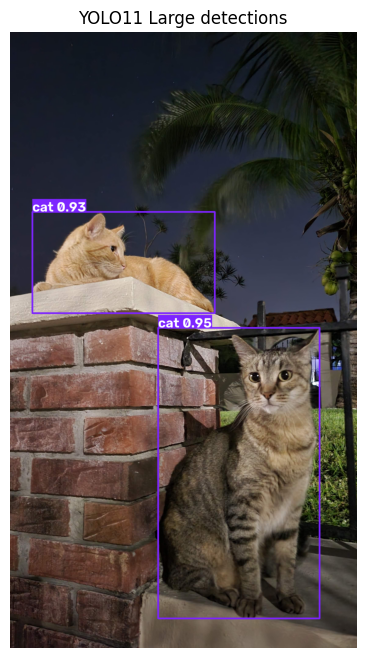

Detected with YOLO11 Large:
  cat (95%)
  cat (93%)


In [17]:
# Compare the larger YOLO11 model on the same custom image
large_results = detector_large(my_image)

annotated_large = large_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 8))
plt.imshow(annotated_large)
plt.axis("off")
plt.title("YOLO11 Large detections")
plt.show()

print("Detected with YOLO11 Large:")
for i in range(len(large_results[0].boxes)):
    name = detector_large.names[int(large_results[0].boxes.cls[i])]
    conf = float(large_results[0].boxes.conf[i])
    print(f"  {name} ({conf:.0%})")

##Observations and Thoughts:
The YOLO11 large model detected the same two cats as the nano model, but with higher confidence scores: Henry increased from about 91% to 95%, and Gigi increased from about 83% to 93%. The improvement came at a significant speed cost, with inference increasing from about 143 ms to about 1.9 seconds. This demonstrates the tradeoff between model size, confidence, and processing speed.

Although the difference in inference time seems small for one image, it could become significant when processing thousands of images or real-time video, making model speed an important deployment consideration.

---

#Try open-vocabulary detection


In [18]:
from ultralytics import YOLOWorld

# Load YOLO-World
world_model = YOLOWorld("yolov8s-worldv2.pt")

# Tell it exactly what we want it to look for
world_model.set_classes(["cat", "palm tree"])

print("YOLO-World loaded with custom classes.")

requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 18 packages in 718ms
Prepared 2 packages in 2.72s
Installed 2 packages in 2ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@a13192f8cb767260d7dfd98c843b0716593169e7)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 229MiB/s]


YOLO-World loaded with custom classes.



image 1/1 /content/Henry-Gigi.jpg: 640x384 2 cats, 466.0ms
Speed: 5.5ms preprocess, 466.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 384)


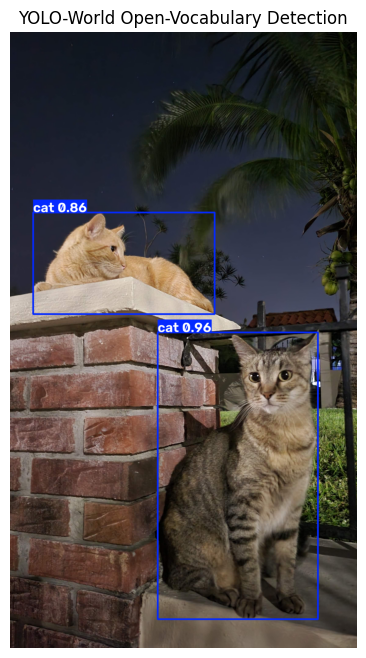

Detected:
  cat: 96%
  cat: 86%


In [19]:
# Run open-vocabulary detection on the custom image
world_results = world_model.predict(my_image, conf=0.10)

annotated_world = world_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 8))
plt.imshow(annotated_world)
plt.axis("off")
plt.title("YOLO-World Open-Vocabulary Detection")
plt.show()

print("Detected:")
for i in range(len(world_results[0].boxes)):
    class_id = int(world_results[0].boxes.cls[i])
    name = world_model.names[class_id]
    conf = float(world_results[0].boxes.conf[i])
    print(f"  {name}: {conf:.0%}")


image 1/1 /content/Henry-Gigi.jpg: 640x384 2 cats, 2 trees, 688.5ms
Speed: 7.9ms preprocess, 688.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 384)


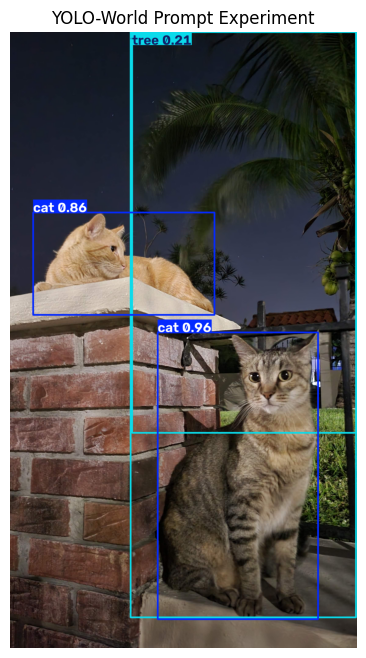

Detected:
  cat: 96%
  cat: 86%
  tree: 21%
  tree: 10%


In [20]:
# Try several open-vocabulary prompts for the palm tree
test_classes = ["cat", "tree", "palm", "palm tree"]

world_model.set_classes(test_classes)

prompt_results = world_model.predict(my_image, conf=0.05)

annotated_prompts = prompt_results[0].plot()[..., ::-1]

plt.figure(figsize=(10, 8))
plt.imshow(annotated_prompts)
plt.axis("off")
plt.title("YOLO-World Prompt Experiment")
plt.show()

print("Detected:")
for i in range(len(prompt_results[0].boxes)):
    class_id = int(prompt_results[0].boxes.cls[i])
    name = world_model.names[class_id]
    conf = float(prompt_results[0].boxes.conf[i])
    print(f"  {name}: {conf:.0%}")

## Observations
###Trying to identify the palm tree:
YOLO-World successfully detected both cats using a custom open-vocabulary class list but did not detect the palm tree, even when “palm tree” was included as a prompt. This shows that open-vocabulary detection expands the range of possible categories, but it does not guarantee successful detection for every object, especially when the object is partially visible or visually complex.

###Second try:
In the first YOLO-World test, the palm tree was not detected when I used the prompt “palm tree.” When I expanded the custom class list to include “tree,” “palm,” and “palm tree” and lowered the confidence threshold to 0.05, the model produced two “tree” detections at 21% and 10% confidence. This shows that open-vocabulary detection can recognize objects outside the standard COCO classes, but the wording of the prompt and the confidence threshold can strongly affect the result.

---

#Compare SAM 2 to SAM 3
###Look up the differences and write a short paragraph in your journal on what changed and why it matters for production CV.

SAM 2 can segment and track objects in images and videos when it is given visual prompts such as points, boxes, or masks. SAM 3 expands this by adding text- and exemplar-prompted segmentation, so it can find and segment all instances of a concept described with a phrase such as “yellow school bus,” without first needing a separate detector to provide boxes. This matters for production computer vision because it can simplify pipelines that previously needed one model for detection and another for segmentation, while also making the system more flexible for open-vocabulary tasks. The tradeoff is that SAM 3 is much larger and heavier than SAM 2, so deployment still requires balancing capability against speed and compute requirements.

---

#Train on your own data

In [21]:
import zipfile
import os

zip_path = "/content/cat_finetune_images.zip"
extract_path = "/content/cat_finetune_images"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipped files:")
print(os.listdir(extract_path))

Unzipped files:
['henry_outdoor_palm.jpg', 'gigi_distant_wall.jpg', 'henry_gigi_outdoor.jpg', 'gigi_indoor_lounge.jpg', 'henry_ottoman.jpg', 'gigi_playing.jpg', 'henry_bed.jpg', 'henry_bed_close.jpg', 'gigi_outdoor_palm.jpg', 'henry_extreme_closeup.jpg', 'henry_desk.jpg']


In [22]:
from pathlib import Path

image_dir = Path("/content/cat_finetune_images")
label_dir = Path("/content/cat_finetune_labels")
label_dir.mkdir(exist_ok=True)

# COCO class ID for "cat" in the pretrained YOLO model
cat_class_id = 15

image_files = sorted(image_dir.glob("*.jpg"))

for img_path in image_files:
    results = detector(img_path, conf=0.25, verbose=False)
    boxes = results[0].boxes

    label_lines = []

    for i in range(len(boxes)):
        detected_class = int(boxes.cls[i])

        if detected_class == cat_class_id:
            # xywhn = normalized x-center, y-center, width, height
            x_center, y_center, width, height = boxes.xywhn[i].tolist()

            # Our custom dataset has only ONE class:
            # class 0 = cat
            label_lines.append(
                f"0 {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

    label_path = label_dir / f"{img_path.stem}.txt"

    with open(label_path, "w") as f:
        f.write("\n".join(label_lines))

    print(f"{img_path.name}: {len(label_lines)} cat(s)")

gigi_distant_wall.jpg: 1 cat(s)
gigi_indoor_lounge.jpg: 1 cat(s)
gigi_outdoor_palm.jpg: 1 cat(s)
gigi_playing.jpg: 0 cat(s)
henry_bed.jpg: 1 cat(s)
henry_bed_close.jpg: 1 cat(s)
henry_desk.jpg: 1 cat(s)
henry_extreme_closeup.jpg: 1 cat(s)
henry_gigi_outdoor.jpg: 2 cat(s)
henry_ottoman.jpg: 1 cat(s)
henry_outdoor_palm.jpg: 1 cat(s)



image 1/1 /content/cat_finetune_images/gigi_playing.jpg: 640x480 1 cat, 1 dog, 1 sports ball, 1585.9ms
Speed: 5.5ms preprocess, 1585.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


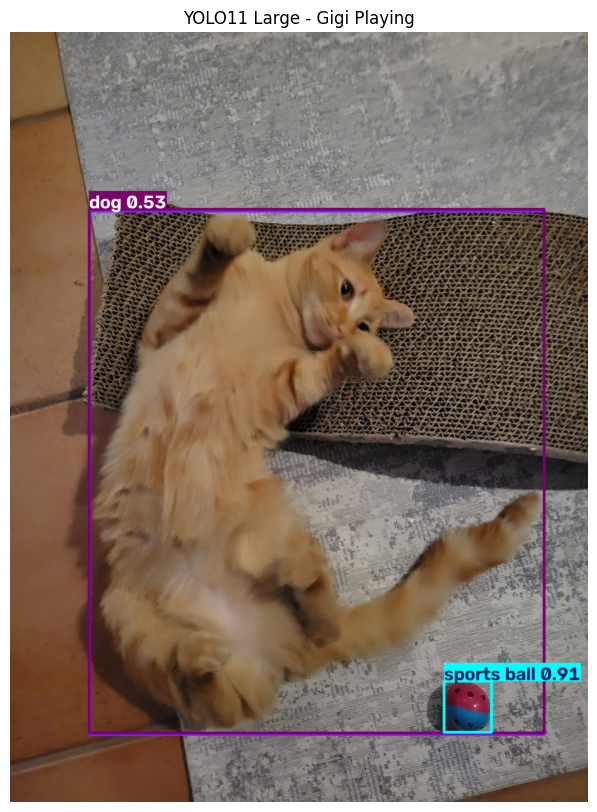

sports ball: 91%
dog: 53%
cat: 48%


In [23]:
missing_image = "/content/cat_finetune_images/gigi_playing.jpg"

gigi_result = detector_large(missing_image, conf=0.10)

annotated = gigi_result[0].plot()[..., ::-1]

plt.figure(figsize=(8, 10))
plt.imshow(annotated)
plt.axis("off")
plt.title("YOLO11 Large - Gigi Playing")
plt.show()

for i in range(len(gigi_result[0].boxes)):
    name = detector_large.names[int(gigi_result[0].boxes.cls[i])]
    conf = float(gigi_result[0].boxes.conf[i])
    print(f"{name}: {conf:.0%}")

In [24]:
# Replace Gigi's missing label using YOLO11 Large's cat detection

cat_lines = []

for i in range(len(gigi_result[0].boxes)):
    detected_class = int(gigi_result[0].boxes.cls[i])

    # COCO cat class = 15
    if detected_class == 15:
        x_center, y_center, width, height = (
            gigi_result[0].boxes.xywhn[i].tolist()
        )

        cat_lines.append(
            f"0 {x_center:.6f} {y_center:.6f} "
            f"{width:.6f} {height:.6f}"
        )

label_path = "/content/cat_finetune_labels/gigi_playing.txt"

with open(label_path, "w") as f:
    f.write("\n".join(cat_lines))

print("Updated gigi_playing.txt")
print(cat_lines)

Updated gigi_playing.txt
['0 0.531080 0.572329 0.786657 0.679591']


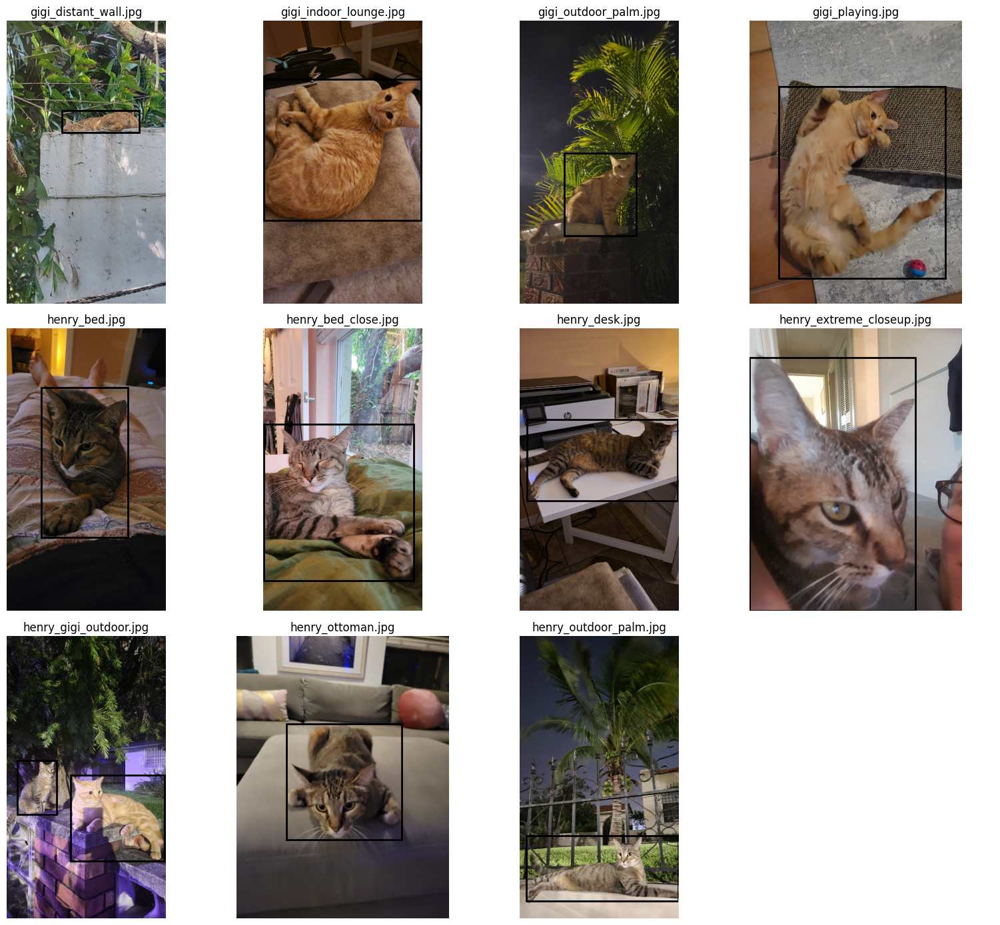

In [25]:
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(3, 4, figsize=(16, 14))
axes = axes.flatten()

for ax, img_path in zip(axes, sorted(image_dir.glob("*.jpg"))):
    img = Image.open(img_path)
    w, h = img.size

    ax.imshow(img)
    ax.axis("off")
    ax.set_title(img_path.name)

    label_path = label_dir / f"{img_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        for line in lines:
            class_id, xc, yc, bw, bh = map(float, line.split())

            box_w = bw * w
            box_h = bh * h
            x_min = (xc * w) - box_w / 2
            y_min = (yc * h) - box_h / 2

            rect = Rectangle(
                (x_min, y_min),
                box_w,
                box_h,
                fill=False,
                linewidth=2
            )
            ax.add_patch(rect)

# Hide any unused subplot
for ax in axes[len(list(image_dir.glob("*.jpg"))):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
from pathlib import Path
import shutil

dataset_root = Path("/content/cat_dataset")

for split in ["train", "val", "test"]:
    (dataset_root / "images" / split).mkdir(parents=True, exist_ok=True)
    (dataset_root / "labels" / split).mkdir(parents=True, exist_ok=True)

train_names = [
    "gigi_indoor_lounge",
    "gigi_outdoor_palm",
    "gigi_playing",
    "henry_bed",
    "henry_desk",
    "henry_ottoman",
    "henry_gigi_outdoor",
]

val_names = [
    "henry_bed_close",
    "henry_outdoor_palm",
]

test_names = [
    "gigi_distant_wall",
    "henry_extreme_closeup",
]

splits = {
    "train": train_names,
    "val": val_names,
    "test": test_names
}

for split, names in splits.items():
    for name in names:
        shutil.copy(
            image_dir / f"{name}.jpg",
            dataset_root / "images" / split / f"{name}.jpg"
        )
        shutil.copy(
            label_dir / f"{name}.txt",
            dataset_root / "labels" / split / f"{name}.txt"
        )

print("Dataset created:")
for split in ["train", "val", "test"]:
    count = len(list((dataset_root / "images" / split).glob("*.jpg")))
    print(f"{split}: {count} images")

Dataset created:
train: 7 images
val: 2 images
test: 2 images


In [27]:
yaml_text = """
path: /content/cat_dataset
train: images/train
val: images/val
test: images/test

names:
  0: cat
"""

yaml_path = "/content/cat_dataset/data.yaml"

with open(yaml_path, "w") as f:
    f.write(yaml_text.strip())

print(open(yaml_path).read())

path: /content/cat_dataset
train: images/train
val: images/val
test: images/test

names:
  0: cat


In [28]:
# Fine-tune YOLO11 nano on the custom cat dataset

cat_model = YOLO("yolo11n.pt")

train_results = cat_model.train(
    data="/content/cat_dataset/data.yaml",
    epochs=15,
    imgsz=640,
    batch=4,
    project="/content/cat_training",
    name="cat_yolo11n"
)

Ultralytics 8.4.154 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cat_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cat_yolo11n, nbs=64, nms=None, opset=None, opt

In [29]:
from ultralytics import YOLO

# Load the best fine-tuned weights
fine_tuned_model = YOLO(
    "/content/cat_training/cat_yolo11n/weights/best.pt"
)

test_folder = "/content/cat_dataset/images/test"

test_results = fine_tuned_model.predict(
    source=test_folder,
    conf=0.10,
    save=True
)

print("Test complete.")


image 1/2 /content/cat_dataset/images/test/gigi_distant_wall.jpg: 640x384 (no detections), 183.8ms
image 2/2 /content/cat_dataset/images/test/henry_extreme_closeup.jpg: 640x480 (no detections), 169.4ms
Speed: 14.3ms preprocess, 176.6ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
Test complete.


#Observations
I fine-tuned YOLO11 nano on a custom cat dataset built from photos of Henry and Gigi. I used 7 training images, 2 validation images, and 2 held-out test images. Although training completed successfully, the validation precision, recall, and mAP were all 0, and the fine-tuned model produced no detections on either test image at a 0.10 confidence threshold. This showed that the dataset was far too small for the model to generalize, and that successful fine-tuning depends heavily on having enough varied, accurately labeled training data.

Interestingly, the original pretrained model detected most of these cats successfully, which shows that fine-tuning on an inadequate custom dataset can actually make performance worse rather than better.

#Reflection
This last challenge was intensive, as this is the first time I have created my own small dataset to train. ChatGPT guided me through the coding steps and helped me understand the output. It was so interesting and fun to explore.

---

## You're Done!

You can now detect and segment with the same tools real CV engineers use in 2026.

You have a project idea for the midterm. The next steps are:

- Finalize your project proposal.
- Start collecting or finding your data.
- Begin Version 1 (your midterm baseline).

Email or message me if you have any questions.

**End of Lab 06.**